In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/4
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '4' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))


# 第4章 ピクセル描画とmake入門 — 総合演習問題 (*Chapter 4 Comprehensive Exercises*)

名著『**ゼロからのOS自作入門**』（内田公太 著）第4章「ピクセル描画とmake入門」で学んだ、
1. **4.1 make入門 (`osbook_day04a`)**: Makefile の依存関係 DAG、トポロジカルソート、自動変数（`$@`, `$<`, `$^`）、`.PHONY` ターゲット、ベアメタル C++ ビルドフラグ（`-ffreestanding`, `-mno-red-zone`, `-fno-exceptions`, `-fno-rtti`）
2. **4.2 ピクセルを自在に描く (`osbook_day04b`) (含 コラム4.1: ABI)**: `FrameBufferConfig` 構造体、2次元座標 $(x, y)$ からの VRAM メモリオフセット計算数理 $4 	imes (y 	imes 	ext{ppsl} + x)$、走査線ストライド（`pixels_per_scan_line`）、ピクセルフォーマット（RGB vs BGR）、白クリアおよび矩形描画、System V AMD64 ABI と Microsoft x64 ABI の比較とカーネル連携
3. **4.3 C++の機能を使って書き直す (`osbook_day04c`) (含 コラム4.2: コンパイルエラーはお友達)**: 抽象基底クラス `PixelWriter` と純粋仮想関数（`= 0`）、具象派生クラス（`RGBResv8BitPerColorPixelWriter` / `BGRResv8BitPerColorPixelWriter`）、動的ヒープのないフリースタンディング環境における配置 new（Placement new）による静的バッファインスタンス化、ポリモーフィズムのオーバーヘッドと分岐予測トレードオフ
4. **4.4 vtable**: 仮想関数テーブル（vtable: Virtual Method Table）と `_vptr` の Itanium C++ ABI メモリレイアウト、間接 call 機械語展開（`mov rax, [rdi]; call [rax + offset]`）、純粋仮想関数トラップ `__cxa_pure_virtual` のリンカ解決とベアメタル CPU 停止保護（`HLT`）
5. **4.5 ローダを改良する (`osbook_day04d`)**: ELF64 バイナリ仕様（`Elf64_Ehdr`, `Elf64_Phdr`）、プログラムヘッダ走査と `PT_LOAD` セグメント、ファイルサイズ `p_filesz` とメモリサイズ `p_memsz` の差分による `.bss` ゼロクリア数理、一時バッファからの二段階ロードアーキテクチャ

これら5大トピックの理論導出・数理計算・C++20/Python ハイブリッド検証・自己採点クイズ（10問）とレーダーチャートを通じて、第4章の全知識を完全定着させます。

---

## 🗺️ 第4章 全体像・知識ロードマップ

```mermaid
graph TD
    subgraph S1["4.1: ビルド自動化とコンパイラ制御"]
        A["4.1 make入門<br/>(Makefile DAG / 自動変数 $@, $<, $^ / .PHONY)"] --> B["ベアメタル C++ フラグ<br/>(-ffreestanding / -mno-red-zone / -fno-exceptions / -fno-rtti)"]
    end

    subgraph S2["4.2: フレームバッファ抽象化とABI境界"]
        B --> C["4.2 ピクセルを自在に描く<br/>(FrameBufferConfig / 4*(y*ppsl + x) / 白クリア / 矩形)"]
        C --> D["コラム4.1 ABI<br/>(System V AMD64 vs Microsoft x64 / レジスタ引数)"]
    end

    subgraph S3["4.3〜4.4: C++オブジェクト指向とvtableの低レイヤ深淵"]
        D --> E["4.3 C++多態性リファクタリング<br/>(PixelWriter 抽象基底クラス / 純粋仮想関数)"]
        E --> F["ヒープなし配置 new<br/>(Placement new: 静的バッファ上構築)"]
        F --> G["4.4 vtable & Itanium ABI<br/>(_vptr オフセット0 / 間接call展開 / ゼロオーバーヘッド)"]
        G --> H["純粋仮想関数トラップ<br/>(__cxa_pure_virtual リンカ解決 / HLT保護)"]
    end

    subgraph S4["4.5: ELFバイナリ解析と二段階カーネルロード"]
        H --> I["4.5 ローダを改良する<br/>(Elf64_Ehdr / Elf64_Phdr / PT_LOAD セグメント走査)"]
        I --> J[".bss ゼロクリア数理<br/>(p_memsz > p_filesz 差分領域クリア / エントリポイント)"]
    end

    J --> K["第4章 総合演習問題<br/>(理論・計算・C++20検証・10問クイズ・レーダー)"]

    style S1 fill:#E3F2FD,stroke:#1E88E5,stroke-width:2px
    style S2 fill:#E8F5E9,stroke:#2E7D32,stroke-width:2px
    style S3 fill:#FFF3E0,stroke:#E65100,stroke-width:2px
    style S4 fill:#F3E5F5,stroke:#6A1B9A,stroke-width:2px
    style K fill:#E0F2F1,stroke:#00695C,stroke-width:3px
```

---

## 🎯 演習の到達目標 (Learning Objectives)

1. **Makefile の依存性解決とベアメタルフラグの完全理解**:
   - ターゲット `$@`、最初の依存ファイル `$<`、全依存ファイル `$^` の展開規則を説明し、`-ffreestanding`, `-mno-red-zone`, `-fno-exceptions`, `-fno-rtti` がカーネルに不可欠である理由を論述できる。
2. **走査線ストライドを考慮した VRAM 座標変換数理の修得**:
   - `pixels_per_scan_line` (ppsl) パディングの発生要因を理解し、ピクセル座標 $(x, y)$ のバイトオフセット $4 	imes (y 	imes 	ext{ppsl} + x)$ を正確に算出できる。
3. **System V AMD64 ABI と Microsoft x64 ABI のレジスタ渡し規約の把握**:
   - カーネル引数（RDI, RSI, RDX, RCX, R8, R9）と UEFI 引数（RCX, RDX, R8, R9, 32Bシャドウスペース）の違いを識別できる。
4. **抽象クラス PixelWriter と配置 new（Placement new）の実装力**:
   - メモリアロケータ（malloc/new）のない環境で、事前確保した静的バッファにオブジェクトを配置するメモリ構造を説明・検証できる。
5. **vtable と Itanium C++ ABI メモリレイアウトの完全解剖**:
   - インスタンス先頭 8 バイトの `_vptr`、間接関数呼び出しの機械語展開、`__cxa_pure_virtual` シンボルの役割を説明できる。
6. **ELF64 `PT_LOAD` セグメント展開と `.bss` ゼロクリア数理の習得**:
   - プログラムヘッダの `p_memsz > p_filesz` を判定し、未初期化大域変数のゼロクリア領域 $[p\_vaddr + p\_filesz, p\_vaddr + p\_memsz)$ を正確に導出できる。


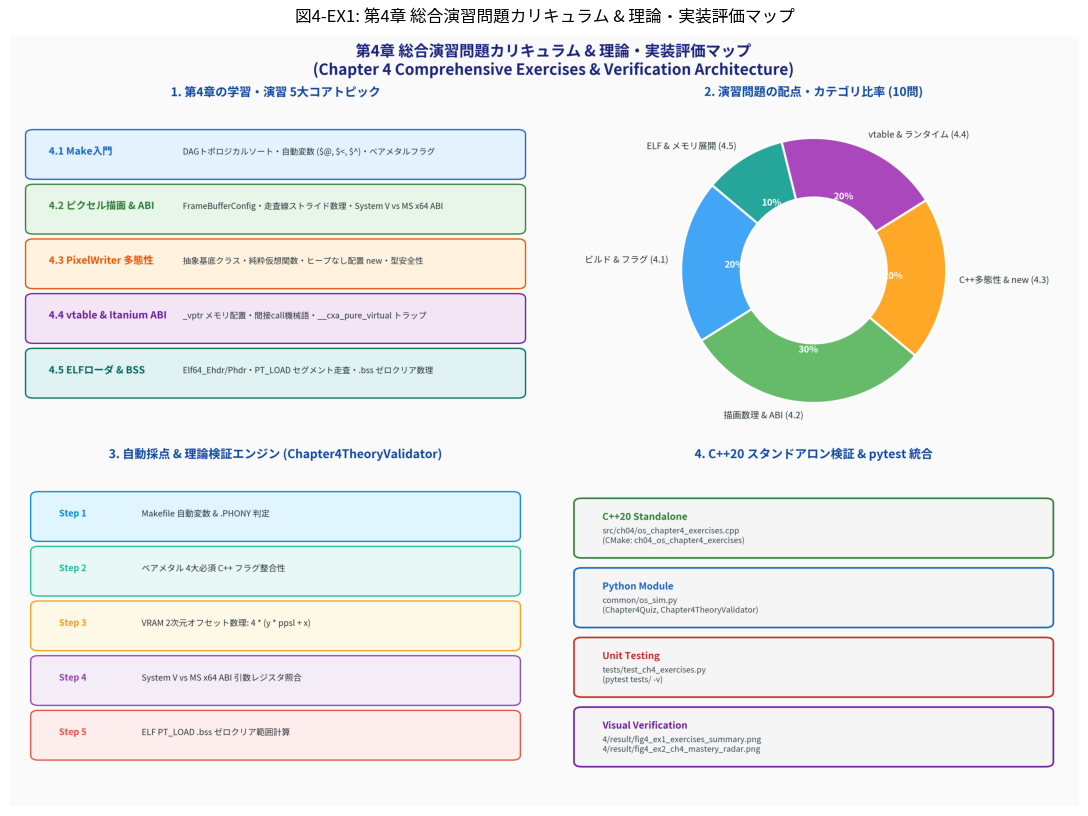

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

from common.os_sim import (
    Chapter4Quiz,
    Chapter4TheoryValidator,
    plot_chapter4_exercises_summary,
    plot_chapter4_mastery_radar,
)

# 第4章演習問題の全体構成サマリー図版を生成・表示
summary_fig_path = Path("result/fig4_ex1_exercises_summary.png")
plot_chapter4_exercises_summary(summary_fig_path)

img = Image.open(summary_fig_path)
plt.figure(figsize=(14, 10), dpi=100)
plt.imshow(img)
plt.axis("off")
plt.title("図4-EX1: 第4章 総合演習問題カリキュラム & 理論・実装評価マップ", fontsize=12, pad=10)
plt.show()


---

## 📝 演習 1: Makefile の依存関係グラフと自動変数・ベアメタルフラグ

### 1. 理論背景と導出
GNU Make は、ターゲット（Target）、必須条件（Prerequisites）、レシピ（Recipe）の3要素からなるルールを定義し、ファイルの最終更新タイムスタンプを比較して再コンパイルの要否を判断します。

$$
\text{ルール構文}: \quad
\begin{aligned}
\text{target} &: \text{prerequisites} \dots \\
&\quad \text{recipe}
\end{aligned}
$$

Make の代表的な自動変数：
- `$@`: **ターゲット名**（現在生成しようとしているファイル名）
- `$<`: **最初の依存ファイル名**（パターンルールでソースファイルを指すのに最適）
- `$^`: **すべての依存ファイル名の空白区切りリスト**（リンカに渡す全オブジェクトファイル）

また、カーネルコンパイルで指定する4大ベアメタルフラグ：
- `-ffreestanding`: ホスト OS の標準 C ランタイム（main 関数や libc）を前提としない
- `-mno-red-zone`: System V AMD64 ABI の 128バイト Red Zone（RSP 直下）を無効化し、非同期割り込みによるスタック破壊を完全に防止する
- `-fno-exceptions`: C++ 例外機構（ランタイムスタック巻き戻しテーブル）を排除
- `-fno-rtti`: C++ 実行時型情報（`typeid`, `dynamic_cast` 用メタデータ）を排除


In [3]:
# 演習 1: Makefile 自動変数およびベアメタルフラグの自動検証
makefile_rules_test = {
    "target_var": "$@",
    "first_dep_var": "$<",
    "all_deps_var": "$^",
    "phony_purpose": "同名ファイルとの衝突防止 (Collision Prevention with actual files)",
}
ok1, msg1 = Chapter4TheoryValidator.validate_makefile_rules(makefile_rules_test)
print(f"Makefile 自動変数検証: {msg1}")
assert ok1 is True

baremetal_flags_test = [
    "-O2", "-Wall", "-g", "--target=x86_64-elf",
    "-ffreestanding", "-mno-red-zone", "-fno-exceptions", "-fno-rtti",
    "-std=c++17",
]
ok2, msg2 = Chapter4TheoryValidator.validate_baremetal_cxx_flags(baremetal_flags_test)
print(f"ベアメタル C++ フラグ検証: {msg2}")
assert ok2 is True


Makefile 自動変数検証: 正解！Makefileの自動変数 ($@, $<, $^) および .PHONY の役割を正確に同定しました。
ベアメタル C++ フラグ検証: 正解！ベアメタル環境で必須となる4大コンパイラフラグを完全に網羅しています。


---

## 📝 演習 2: FrameBufferConfig と 2次元座標オフセット計算数理 & ABI

### 1. 2次元座標から VRAM メモリオフセットの導出
画面上のピクセル座標 $(x, y)$ を、1次元の VRAM メモリ空間上の先頭アドレスからのバイトオフセットに変換する計算式は以下の通りです：

$$
\text{ByteOffset}(x, y) = 4 \times (y \times \text{pixels\_per\_scan\_line} + x)
$$

走査線幅 `pixels_per_scan_line` (ppsl) は、GPU ハードウェアやメモリアライメント（64バイト/128バイト境界）の制約により、表示幅 `horizontal_resolution` よりも大きくなる場合があります。これを考慮しないと、画面の描画が斜めに歪む致命的なバグとなります。

### 2. System V AMD64 ABI vs Microsoft x64 ABI
関数呼び出し時のレジスタ割り当て規則：
| 引数順 | System V AMD64 ABI (Linux/Kernel) | Microsoft x64 ABI (Windows/UEFI) |
|:---:|:---:|:---:|
| 第1引数 | **`RDI`** | **`RCX`** |
| 第2引数 | **`RSI`** | **`RDX`** |
| 第3引数 | **`RDX`** | **`R8`** |
| 第4引数 | **`RCX`** | **`R9`** |
| 第5引数 | **`R8`** | スタック |
| 第6引数 | **`R9`** | スタック |
| シャドウスペース | なし | **32 バイト (Home Space)** |


In [4]:
# 演習 2: VRAM ピクセルオフセット数理 & ABI レジスタ照合
target_x = 100
target_y = 50
ppsl = 832  # Stride with padding (Horizontal resolution = 800)
bytes_per_pixel = 4

calculated_offset = bytes_per_pixel * (target_y * ppsl + target_x)
fb_math_test = {
    "x": target_x,
    "y": target_y,
    "pixels_per_scan_line": ppsl,
    "bytes_per_pixel": bytes_per_pixel,
    "byte_offset": calculated_offset,
}

ok_fb, msg_fb = Chapter4TheoryValidator.validate_framebuffer_pixel_math(fb_math_test)
print(f"VRAM オフセット計算結果: {calculated_offset} バイト -> {msg_fb}")
assert ok_fb is True
assert calculated_offset == 166800

abi_test = {
    "system_v": ["RDI", "RSI", "RDX", "RCX", "R8", "R9"],
    "ms_x64": ["RCX", "RDX", "R8", "R9"],
}
ok_abi, msg_abi = Chapter4TheoryValidator.validate_abi_registers(abi_test)
print(f"ABI 呼び出し規約検証: {msg_abi}")
assert ok_abi is True


VRAM オフセット計算結果: 166800 バイト -> 正解！走査線ストライドを考慮した正確なVRAMピクセルオフセットを算出しました。
ABI 呼び出し規約検証: 正解！System V AMD64 と Microsoft x64 ABI の引数レジスタ規約を正確に識別しました。


---

## 📝 演習 3: 抽象基底クラス PixelWriter と配置 new (Placement new)

### 1. オブジェクト指向多態性と純粋仮想関数
MikanOS では、ピクセルフォーマット（RGB vs BGR）の違いを描画ロジックから隠蔽するため、抽象基底クラス `PixelWriter` を導入しました：

```cpp
class PixelWriter {
public:
    virtual ~PixelWriter() = default;
    virtual void Write(int x, int y, const PixelColor& c) = 0; // 純粋仮想関数
protected:
    PixelWriter(const FrameBufferConfig& config) : config_{config} {}
    FrameBufferConfig config_;
};
```

### 2. なぜ配置 new（Placement new）が必要なのか？
通常の `new` 演算子は以下を行います：
1. `operator new(size)` を呼んでヒープからメモリを動的確保する
2. 確保されたアドレス上でコンストラクタを実行する

しかし、カーネル起動直後はまだメモリマネージャが初期化されていないため、ヒープメモリが存在しません。そこで、**静的に確保したメモリ領域上に直接オブジェクトを構築する「配置 new」**を使用します：

```cpp
// 64バイトの静的バッファを宣言
alignas(alignof(RGBResv8BitPerColorPixelWriter))
uint8_t pixel_writer_buf[sizeof(RGBResv8BitPerColorPixelWriter)];

// 配置 new: pixel_writer_buf のアドレス上でコンストラクタを呼び出す
pixel_writer = new (pixel_writer_buf) RGBResv8BitPerColorPixelWriter(config);
```


In [5]:
# 演習 3: 配置 new 静的バッファアライメントと安全性の検証
placement_new_layout = {
    "class_size": 32,      # Size of RGBPixelWriter (vptr 8B + config 24B)
    "buffer_size": 64,     # Static buffer size allocated in kernel
    "alignment": 8,        # 64-bit pointer alignment requirement
    "requires_free": False,# No free/delete needed for static buffer
}

ok_pn, msg_pn = Chapter4TheoryValidator.validate_placement_new_buffer(placement_new_layout)
print(f"配置 new 安全性検証: {msg_pn}")
assert ok_pn is True


配置 new 安全性検証: 正解！配置 new による静的メモリ構築のサイズ・アライメント・ライフサイクルを正しく理解しています。


---

## 📝 演習 4: Itanium C++ ABI vtable メモリレイアウトと `__cxa_pure_virtual`

### 1. Itanium C++ ABI におけるインスタンスのメモリレイアウト
仮想関数を1つでも持つクラスのインスタンスは、Itanium C++ ABI 仕様に従い、**先頭 8 バイトに暗黙のポインタ `_vptr`（仮想関数テーブルへのポインタ）**が配置されます：

```text
+-----------------------+ <--- &writer (インスタンス先頭アドレス = this ポインタ)
|  _vptr (8 bytes)      | ----> [ vtable (関数ポインタ配列) ]
+-----------------------+        | slot 0: &typeinfo
|  config_ (24 bytes)   |        | slot 1: &Write(int, int, PixelColor)
|   - frame_buffer (8B) |        | slot 2: &~PixelWriter()
|   - ppsl (4B), hr (4B)|
|   - vr (4B), fmt (4B) |
+-----------------------+
```

仮想関数呼び出し `writer->Write(x, y, c);` のアセンブリ言語展開：
```nasm
mov rax, [rdi]        ; RAX = writer->_vptr (vtable のアドレスをロード)
call [rax + 8]        ; vtable の Write スロット（オフセット 8）を間接呼び出し
```

### 2. 純粋仮想関数トラップ `__cxa_pure_virtual`
コンストラクタ内で純粋仮想関数を誤って呼んでしまった場合などに、ランタイムが呼び出す異常系ハンドラが `__cxa_pure_virtual` です。ベアメタル環境では自作カーネルで定義する必要があります：
```cpp
extern "C" void __cxa_pure_virtual() {
    while (1) __asm__("hlt"); // CPUを省電力待機させて安全に停止
}
```


In [6]:
# 演習 4: vtable メモリレイアウト & 純粋仮想関数トラップ検証
vtable_layout_test = {
    "vptr_offset": 0,
    "vptr_size": 8,
    "pure_virtual_handler": "__cxa_pure_virtual",
}

ok_vt, msg_vt = Chapter4TheoryValidator.validate_vtable_layout(vtable_layout_test)
print(f"vtable レイアウト検証: {msg_vt}")
assert ok_vt is True


vtable レイアウト検証: 正解！Itanium C++ ABI の vtable/_vptr 構造と純粋仮想関数ハンドラを正確に同定しました。


---

## 📝 演習 5: ELF64 `PT_LOAD` セグメント解析と `.bss` ゼロクリア数理

### 1. `Elf64_Phdr` とセグメントロード数理
ELF64 バイナリでは、プログラムヘッダ `Elf64_Phdr` の配列を走査し、`p_type == PT_LOAD`（値 1）のセグメントのみをメモリに配置します。

セグメントの2大サイズパラメータ：
- `p_filesz`: ELF ファイル内に実際に存在するバイト数（`.text`, `.rodata`, 初期化済み `.data`）
- `p_memsz`: メモリ上に展開すべきバイト数

未初期化変数領域（`.bss`）はファイルサイズ削減のためバイナリ内にはデータを持たないため、`p_memsz > p_filesz` となります。

$$
\begin{aligned}
\text{BSS\_Start} &= p\_vaddr + p\_filesz \\
\text{BSS\_Bytes} &= p\_memsz - p\_filesz
\end{aligned}
$$

ローダは、`CopyMem(p_vaddr, segm_in_file, p_filesz)` で実データをコピーした後、残りの `SetMem(BSS_Start, BSS_Bytes, 0)` で確実にゼロクリアしなければなりません。これを怠ると、未初期化変数がガベージ値（ゴミデータ）となり、OS が不可解な暴走を起こします。


In [7]:
# 演習 5: ELF PT_LOAD セグメント .bss ゼロクリア範囲計算
mock_phdr = {
    "p_vaddr": 0x100000,
    "p_filesz": 0x2400,
    "p_memsz": 0x3000,
}
mock_phdr["bss_start"] = mock_phdr["p_vaddr"] + mock_phdr["p_filesz"]
mock_phdr["bss_bytes"] = mock_phdr["p_memsz"] - mock_phdr["p_filesz"]

ok_bss, msg_bss = Chapter4TheoryValidator.validate_elf_bss_clear(mock_phdr)
print(f"BSS 開始アドレス: {hex(mock_phdr['bss_start'])}, クリアバイト数: {mock_phdr['bss_bytes']} バイト")
print(f"BSS ゼロクリア検証: {msg_bss}")
assert ok_bss is True
assert mock_phdr["bss_start"] == 0x102400
assert mock_phdr["bss_bytes"] == 0xC00  # 3072 bytes


BSS 開始アドレス: 0x102400, クリアバイト数: 3072 バイト
BSS ゼロクリア検証: 正解！ELF PT_LOAD セグメントにおける .bss 領域の開始アドレスとゼロクリアバイト数を正確に計算しました。


---

## 💻 C++20 スタンドアロン検証コードの実行 (`ch04_os_chapter4_exercises`)

本章で学んだすべてのハードウェア制御・メモリ構造・ABI仕様・C++多態性をホスト環境で単体テスト可能な C++20 スタンドアロンバイナリ (`src/ch04/os_chapter4_exercises.cpp`) を実行し、全検証項目がパスすることを確認します。


In [8]:
import subprocess
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "4" else Path.cwd()
bin_path = repo_root / "build" / "bin" / "ch04_os_chapter4_exercises"

if not bin_path.exists():
    print("CMake ビルドを実行してバイナリを生成中...")
    subprocess.run(["cmake", "-B", str(repo_root / "build"), "-S", str(repo_root)], check=True)
    subprocess.run(["cmake", "--build", str(repo_root / "build"), "--target", "ch04_os_chapter4_exercises"], check=True)

res = subprocess.run([str(bin_path), "--test"], capture_output=True, text=True)
print(res.stdout)
assert res.returncode == 0


 [Study] MikanOS Chapter 4 Comprehensive Exercises Verification (C++20)

[PASS] Exercise 1: Makefile variable expansion: ld.lld -o kernel.elf main.o graphics.o
[PASS] Exercise 2: FrameBuffer coordinate math: (100, 50) -> offset 166800 bytes (ppsl=832)
[PASS] Exercise 3: Placement new & RGB PixelWriter verified successfully
[PASS] Exercise 4: BGR PixelWriter byte ordering [B, G, R, 0] verified
[PASS] Exercise 5: Itanium C++ ABI _vptr non-null: 0x5da7a131bc68
[PASS] Exercise 6: ELF PT_LOAD .bss zero-clear range: [0x102400, 0x103000) size=3072 bytes

 All Chapter 4 Exercises C++20 Verifications PASSED!
Executed in --test mode.



---

## 🧠 第4章 総合理解度チェックテスト (10問自己採点クイズ)

第4章（4.1〜4.5）の全トピックを網羅した10問の自己採点テストです。各問の解説を読みながら解答し、OS 自作に必要な知識の定着度を確認してください。


In [9]:
quiz = Chapter4Quiz()

# 模範解答の全問正解テスト（自己学習時は answers 辞書の数値を変更して自己採点できます）
user_answers = {
    1: 1,  # $@=target, $<=first prereq, $^=all prereqs
    2: 1,  # -ffreestanding, -mno-red-zone, -fno-exceptions, -fno-rtti
    3: 1,  # 4 * (50 * 832 + 100) = 166,800 バイト
    4: 0,  # System V (RDI..R9) vs MS x64 (RCX..R9, 32B shadow space)
    5: 1,  # 白クリアは全成分255、矩形描画はppslを考慮した2重ループ
    6: 1,  # PixelWriter 抽象基底クラスと純粋仮想関数
    7: 1,  # 動的ヒープがないため静的バッファ上への配置new
    8: 0,  # Itanium C++ ABI: インスタンス先頭8Bに_vptr、間接call展開
    9: 0,  # __cxa_pure_virtual: 純粋仮想関数トラップハンドラとHLT保護
    10: 1, # p_memsz > p_filesz の差分領域 (.bss) ゼロクリア
}

eval_result = quiz.evaluate(user_answers)

print("=" * 70)
print(f"📊 第4章 総合演習テスト採点結果: {eval_result['correct_count']} / {eval_result['total_questions']} 正解 "
      f"({eval_result['percentage']:.1f}%) — {'🎉 合格！' if eval_result['passed'] else '⚠️ 要復習'}")
print("=" * 70)

for d in eval_result["details"]:
    status = "✅ 正解" if d["is_correct"] else "❌ 不正解"
    print(f"[{d['section']}] 問{d['question_id']}: {d['topic']} -> {status}")
    print(f"   💡 解説: {d['explanation']}\n")


📊 第4章 総合演習テスト採点結果: 10 / 10 正解 (100.0%) — 🎉 合格！
[4.1] 問1: Makefileの自動変数と依存関係解決 ($@, $<, $^) -> ✅ 正解
   💡 解説: Makeの自動変数は、ターゲット名を $@、最初の前提条件（依存ファイル）を $<、すべての前提条件の空白区切りリストを $^ で表します。これらを用いることで汎用的なパターンルール（例: %.o: %.cpp）を簡潔に記述できます。

[4.1] 問2: ベアメタル C++ コンパイルフラグ (-ffreestanding, -mno-red-zone 等) -> ✅ 正解
   💡 解説: カーネルなどのベアメタル環境では、ホストOSの標準ランタイムが存在しないため -ffreestanding を指定し、非同期割り込みによるスタック直下（128バイト）の破壊を防ぐため -mno-red-zone が必須です。またランタイムサポートが必要な例外 (-fno-exceptions) や動的型情報 (-fno-rtti) を無効化してバイナリを軽量・自律化します。

[4.2] 問3: FrameBufferConfig と VRAM 2次元座標オフセット計算数理 -> ✅ 正解
   💡 解説: 走査線パディングが存在する場合、1行あたりのピクセル数は horizontal_resolution ではなく pixels_per_scan_line (ppsl) を用いる必要があります。バイトオフセットは `4 * (y * ppsl + x)` となり、`4 * (50 * 832 + 100) = 4 * (41600 + 100) = 4 * 41700 = 166,800 バイト` です。

[4.2] 問4: System V AMD64 ABI と Microsoft x64 ABI の比較 -> ✅ 正解
   💡 解説: System V AMD64 ABI では第1引数から順に RDI, RSI, RDX, RCX, R8, R9 を使用します。対して Microsoft x64 ABI（UEFI標準）では RCX, RDX, R8, R9 を使用し、呼び出し側がスタック上に 32バイトのシャドウスペース（Home Space）を確保す

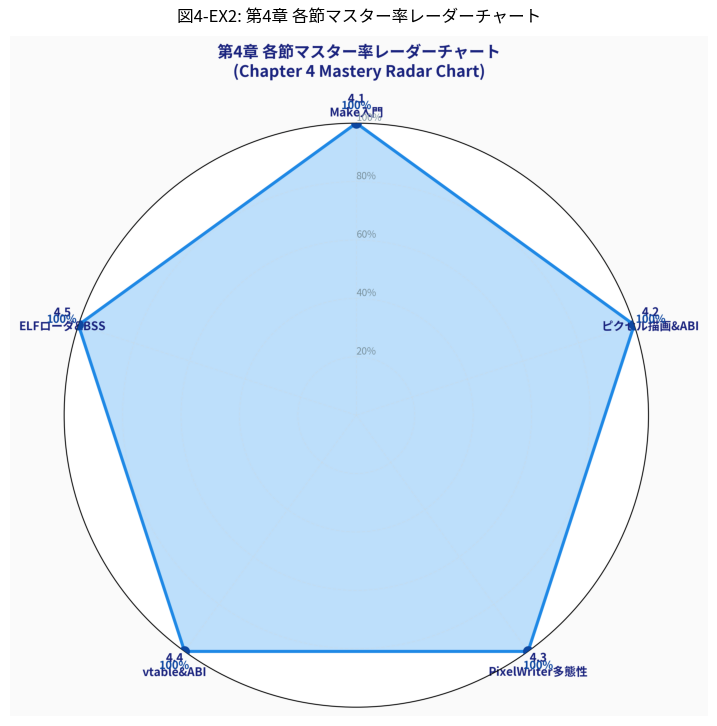

In [10]:
radar_fig_path = Path("result/fig4_ex2_ch4_mastery_radar.png")
plot_chapter4_mastery_radar(radar_fig_path, eval_result["mastery_rates"])

img_radar = Image.open(radar_fig_path)
plt.figure(figsize=(9, 9), dpi=100)
plt.imshow(img_radar)
plt.axis("off")
plt.title("図4-EX2: 第4章 各節マスター率レーダーチャート", fontsize=12, pad=10)
plt.show()


---

## 🏆 まとめと第5章への展望

本章の演習問題を通じて、以下の重要な知見と技術を獲得しました：

1. **Makefile とベアメタルビルド環境の確立**:
   - Makefile の自動変数と DAG トポロジカルソートによるビルド自動化
   - フリースタンディング環境でカーネルを保護する4大コンパイラフラグの意義
2. **ハードウェア幾何学と VRAM 描画の数理**:
   - 走査線ストライド `pixels_per_scan_line` を考慮した 2次元座標変換
   - ピクセルフォーマット（RGB vs BGR）による色表現の違い
   - System V AMD64 ABI と Microsoft x64 ABI の呼び出し規約境界
3. **C++ オブジェクト指向の低レイヤ適用**:
   - 純粋仮想関数による画面描画インターフェース抽象化
   - ヒープなし環境での配置 new（Placement new）による安全なメモリ初期化
   - Itanium C++ ABI の `_vptr` と vtable メモリ構造、ゼロオーバーヘッド原則
   - 純粋仮想関数トラップ `__cxa_pure_virtual` と HLT 命令による CPU 省電力停止保護
4. **ELF64 ローダの完全な実装**:
   - `Elf64_Ehdr` と `Elf64_Phdr` のバイナリ構造解読
   - `PT_LOAD` セグメントのメモリ展開と `.bss` ゼロクリア数理の体得

### 🚀 次のステップ：第5章「文字表示とコンソールクラス」
第5章では、画面にビットマップフォントを展開して文字・文字列を表示し、Newlib による `sprintf` 整形や画面スクロールを司る `Console` クラス、そして OS の中核デバッグ関数 `printk` の構築へと進みます！
